In [1]:
import pandas as pd

architecture_summary = pd.read_csv(
    "../results/tables/architecture_summary.csv"
)

candidate_proteins = pd.read_csv(
    "../results/tables/candidate_proteins.csv"
)

architecture_summary.head()

,domain_architecture,proteins,species,thermophile_species,has_cbm,has_cellulase
0,GH72 + CBM43,48,23,1,True,True
1,GH71 + CBM24,34,19,1,True,True
2,GH15 + CBM20,30,20,2,True,False
3,GH54 + CBM42,28,19,1,True,True
4,AA8 + AA3_1,27,15,3,False,False


In [2]:
architectures = architecture_summary.copy()

In [3]:
arch_list = architectures["domain_architecture"].tolist()

len(arch_list)

47

In [4]:
#Read all proteomes once
from Bio import SeqIO
import os

proteome_dir = "../data/proteomes"

proteins = {}

for file in os.listdir(proteome_dir):

    if not file.endswith(".fasta"):
        continue

    species = file.replace(".fasta","")

    fasta_path = os.path.join(
        proteome_dir,
        file
    )

    for record in SeqIO.parse(fasta_path, "fasta"):

        proteins[record.id] = {
            "species": species,
            "record": record
        }

print(len(proteins))

325138


In [5]:
test_id = candidate_proteins.iloc[0]["query"]

proteins[test_id]["record"]

SeqRecord(seq=Seq('MSFRSLLALSGLVCSGLASVISKRATLDSWLSNEATVARTAILNNIGADGAWVS...TWR'), id='tr|A0A1L9U2T6|A0A1L9U2T6_ASPBC', name='tr|A0A1L9U2T6|A0A1L9U2T6_ASPBC', description='tr|A0A1L9U2T6|A0A1L9U2T6_ASPBC Glucoamylase OS=Aspergillus brasiliensis (strain CBS 101740 / IMI 381727 / IBT 21946) OX=767769 GN=ASPBRDRAFT_70083 PE=3 SV=1', dbxrefs=[])

In [6]:
import os

output_dir = "../results/architecture_fastas"

os.makedirs(
    output_dir,
    exist_ok=True
)

In [7]:
arch_list

['GH72 + CBM43',
 'GH71 + CBM24',
 'GH15 + CBM20',
 'GH54 + CBM42',
 'AA8 + AA3_1',
 'GH43_14 + CBM91',
 'GH13_1 + CBM20',
 'GH43_36 + CBM91',
 'GH7 + CBM1',
 'GH43_29 + CBM6',
 'GH10 + CBM1',
 'GH43_13 + CBM91',
 'AA13 + CBM20',
 'GH5_4 + CBM46',
 'CBM35 + GH26',
 'CE8 + GH28',
 'GH32 + CBM38',
 'GH5_5 + CBM1',
 'CBM87 + CE18',
 'GH18 + CBM24',
 'GH43_34 + CBM66',
 'CBM38 + GH32',
 'GH142 + CBM13',
 'GH18 + CBM19',
 'GH76 + CBM13',
 'AA1_3 + AA1',
 'AA2 + AA5',
 'AA9 + CBM1',
 'CBM1 + GH10',
 'CBM1 + GH45_1',
 'CE1 + CBM1',
 'GH11 + CBM1',
 'GH128 + GH16_4',
 'GH13_1 + GH13_5',
 'GH13_32 + CBM20',
 'GH18 + CBM5',
 'GH27 + GH28',
 'GH30_7 + GH30',
 'GH32 + CBM38 + GH32',
 'GH43_26 + CBM42',
 'GH45_2 + CBM1',
 'GH55 + GH55_2',
 'GH71 + CBM24 + CBM24',
 'GH74 + GH74 + CBM1',
 'GH79 + CBM67 + GH78',
 'GH79 + GH29',
 'GH93 + CBM66']

In [8]:
#Export one FASTA per architecture
from Bio import SeqIO

for arch in arch_list:

    subset = candidate_proteins[
        candidate_proteins["domain_architecture"] == arch
    ]

    records = []

    for protein_id in subset["query"]:

        if protein_id in proteins:

            records.append(
                proteins[protein_id]["record"]
            )

    safe_name = (
        arch
        .replace(" + ", "_")
        .replace("/", "_")
        .replace(" ", "_")
    )

    fasta_out = os.path.join(
        output_dir,
        f"{safe_name}.fasta"
    )

    SeqIO.write(
        records,
        fasta_out,
        "fasta"
    )

print("Done")

Done


In [9]:
summary = []

for arch in arch_list:

    subset = candidate_proteins[
        candidate_proteins["domain_architecture"] == arch
    ]

    summary.append({

        "architecture": arch,

        "proteins":
            subset["query"].nunique(),

        "species":
            subset["species"].nunique()
    })

fasta_summary = pd.DataFrame(summary)

fasta_summary.sort_values(
    "proteins",
    ascending=False
)

,architecture,proteins,species
0,GH72 + CBM43,48,23
1,GH71 + CBM24,34,19
2,GH15 + CBM20,30,20
3,GH54 + CBM42,28,19
4,AA8 + AA3_1,27,15
5,GH43_14 + CBM91,19,14
6,GH13_1 + CBM20,16,14
7,GH43_36 + CBM91,13,9
8,GH7 + CBM1,11,7
9,GH43_29 + CBM6,9,8


In [10]:
fasta_summary.to_csv(
    "../results/tables/architecture_fasta_summary.csv",
    index=False
)

In [11]:
import os

files = sorted(
    os.listdir("../results/architecture_fastas")
)

len(files), files[:10]

(47,
 ['AA13_CBM20.fasta',
  'AA1_3_AA1.fasta',
  'AA2_AA5.fasta',
  'AA8_AA3_1.fasta',
  'AA9_CBM1.fasta',
  'CBM1_GH10.fasta',
  'CBM1_GH45_1.fasta',
  'CBM35_GH26.fasta',
  'CBM38_GH32.fasta',
  'CBM87_CE18.fasta'])

In [12]:
from Bio import SeqIO
import pandas as pd
import os

fasta_dir = "../results/architecture_fastas"

summary = []

for file in os.listdir(fasta_dir):

    if not file.endswith(".fasta"):
        continue

    path = os.path.join(fasta_dir, file)

    lengths = [
        len(record.seq)
        for record in SeqIO.parse(path, "fasta")
    ]

    summary.append({
        "architecture": file.replace(".fasta",""),
        "proteins": len(lengths),
        "mean_length": sum(lengths)/len(lengths),
        "min_length": min(lengths),
        "max_length": max(lengths)
    })

length_df = pd.DataFrame(summary)

length_df.sort_values(
    "proteins",
    ascending=False
)

,architecture,proteins,mean_length,min_length,max_length
40,GH72_CBM43,48,533.083333,467,552
38,GH71_CBM24,34,935.764706,574,1736
19,GH15_CBM20,30,625.366667,578,657
34,GH54_CBM42,28,506.142857,499,543
3,AA8_AA3_1,27,820.925926,676,934
28,GH43_14_CBM91,19,588.421053,553,643
15,GH13_1_CBM20,16,625.500000,606,640
32,GH43_36_CBM91,13,528.076923,508,582
45,GH7_CBM1,11,510.636364,460,540
30,GH43_29_CBM6,9,444.666667,383,461


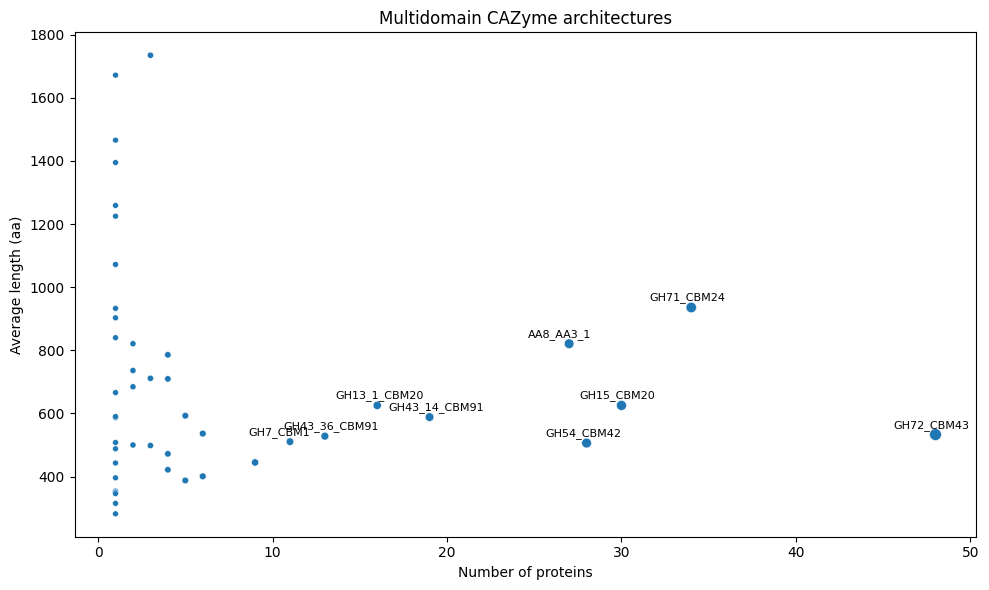

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_df = length_df.sort_values(
    "proteins",
    ascending=False
)

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=plot_df,
    x="proteins",
    y="mean_length",
    size="proteins",
    legend=False
)

for _, row in plot_df.iterrows():

    if row["proteins"] >= 10:

        plt.annotate(
            row["architecture"],
            (row["proteins"], row["mean_length"]),
            xytext=(-30,5),
            textcoords="offset points",
            fontsize=8
        )




plt.xlabel("Number of proteins")
plt.ylabel("Average length (aa)")
plt.title(
    "Multidomain CAZyme architectures"
)

plt.savefig(
    "../results/figures/multidomain_CAZyme_architectures.png",
    dpi=300
)


plt.tight_layout()

plt.show()

In [14]:
#Inspect proteins
from Bio import SeqIO
import pandas as pd
import os

fasta_dir = "../results/architecture_fastas"

proteins = []

for file in os.listdir(fasta_dir):

    if not file.endswith(".fasta"):
        continue

    architecture = file.replace(".fasta", "")

    path = os.path.join(fasta_dir, file)

    for record in SeqIO.parse(path, "fasta"):

        proteins.append({
            "architecture": architecture,
            "protein": record.id,
            "length": len(record.seq)
        })

lengths = pd.DataFrame(proteins)

lengths.head()

,architecture,protein,length
0,AA13_CBM20,tr|A1CN59|A1CN59_ASPCL,385
1,AA13_CBM20,tr|A0A8T8WTI5|A0A8T8WTI5_ASPJA,380
2,AA13_CBM20,sp|Q5B1W7|AA13_EMENI,385
3,AA13_CBM20,sp|Q7SCE9|AA13_NEUCR,385
4,AA13_CBM20,tr|S8AKS0|S8AKS0_PENO1,403


In [15]:
lengths.sort_values(
    "length",
    ascending=False
).head(50)



,architecture,protein,length
111,GH18_CBM24,tr|A0A364L601|A0A364L601_TALAM,2159
226,GH71_CBM24,tr|Q7RV24|Q7RV24_NEUCR,1736
222,GH71_CBM24,tr|Q2GM42|Q2GM42_CHAGB,1722
6,AA2_AA5,tr|A0A698XLC6|A0A698XLC6_TALPI,1672
229,GH71_CBM24,tr|S7ZL85|S7ZL85_PENO1,1619
113,GH18_CBM24,tr|G9ME15|G9ME15_HYPVG,1523
112,GH18_CBM24,tr|A0A2T4A6I8|A0A2T4A6I8_TRIHA,1523
246,GH71_CBM24_CBM24,tr|A0A364KXE8|A0A364KXE8_TALAM,1466
121,GH32_CBM38_GH32,tr|A0A478ECL0|A0A478ECL0_TALPI,1395
298,GH79_CBM67_GH78,tr|A0A5M3YUF2|A0A5M3YUF2_ASPTE,1259


In [16]:
lengths.to_csv(
    "../results/tables/lengths.csv",
    index=False
)


In [17]:
candidate = pd.read_csv(
    "../results/tables/candidate_proteins.csv"
)[["query", "species"]]

lengths = lengths.merge(
    candidate,
    left_on="protein",
    right_on="query",
    how="left"
).drop(columns="query")




In [18]:
candidate

,query,species
0,tr|A0A1L9U2T6|A0A1L9U2T6_ASPBC,aspergillus_brasiliensis
1,tr|A0A1L9U3B6|A0A1L9U3B6_ASPBC,aspergillus_brasiliensis
2,tr|A0A1L9U3Z0|A0A1L9U3Z0_ASPBC,aspergillus_brasiliensis
3,tr|A0A1L9U833|A0A1L9U833_ASPBC,aspergillus_brasiliensis
4,tr|A0A1L9UBN9|A0A1L9UBN9_ASPBC,aspergillus_brasiliensis
...,...,...
307,tr|G9N056|G9N056_HYPVG,trichoderma_virens
308,tr|G9N0W8|G9N0W8_HYPVG,trichoderma_virens
309,tr|G9N1C8|G9N1C8_HYPVG,trichoderma_virens
310,tr|Q6C863|Q6C863_YARLI,yarrowia_lipolytica
